# Two-way time transfer: one-board self-test (27 October 2026)

Board **8873292600AB** (192.168.2.100), RF-clock 1.3.0.8, run `twtt_AB_20261027_232952`: 300 seconds of the two-way time transfer (TWTT) program running on **one board through its own loopback cable**, as the last check before the two-board test.

**Contents**
1. What two-way time transfer measures
2. What the self-test is, and what it can and cannot show
3. Set-up and commands
4. The data: one second worked through by hand
5. Results: completeness and signal quality
6. Results: the two one-way measurements
7. Results: the clock offset θ
8. Results: the one-way delay
9. Stability with averaging (standard deviation of the mean, Allan deviation)
10. Comparison with M3 and with the two-board test of 21 October
11. Summary

## 1. What two-way time transfer measures

Two boards, A and B, each keep their own time: a 100 MHz **tick** counter locked to their 10 MHz reference, and the tick of their latest **PPS** edge. Every time below is counted from the board's own PPS edge of that second. The question TWTT answers is: **by how much does B's clock read differently from A's at the same instant?** That difference is the clock offset $\theta$.

Each second, both directions are measured:

* in slot **AB** (100 ms after the PPS) A transmits a PRN burst and B receives it;
* in slot **BA** (600 ms after the PPS) B transmits and A receives.

Each board timestamps what it does with its own clock, so each one-way measurement mixes the propagation delay with the clock offset:

$$
m_{AB} = T_{rx,B} - T_{tx,A} = d_{t,A} + p + d_{r,B} + \theta
$$
$$
m_{BA} = T_{rx,A} - T_{tx,B} = d_{t,B} + p + d_{r,A} - \theta
$$

where $p$ is the path delay (cables, filter, attenuator), $d_t$ is a board's transmit delay (FPGA → DAC → connector) and $d_r$ its receive delay (connector → ADC → FPGA). The offset enters the two directions with **opposite signs** and the path with the **same sign**, so

$$
\theta = \frac{m_{AB} - m_{BA}}{2} - \frac{\Delta}{2}, \qquad \text{one-way delay} = \frac{m_{AB} + m_{BA}}{2}
$$

The path delay cancels in $\theta$ as long as it is the same both ways (reciprocity). What does not cancel is the **non-reciprocity** $\Delta = (d_{t,A} + d_{r,B}) - (d_{t,B} + d_{r,A})$, the difference of the two boards' hardware delays, which is calibrated once with both boards on the same reference (where the true $\theta$ is 0). The program reports $(m_{AB} - m_{BA})/2$ as `theta_ns`, without that correction.

**How a one-way time is measured** (`rf_clock.twtt.timing.one_way_ns`): the transmitting board arms its burst for an exact tick and reports the tick it actually started on (`TX_ACTUAL`). The receiving board opens a capture window 125 ticks (1.25 µs) before the slot (`RX_ACTUAL`), and the ARM correlates the 800 MS/s capture with the PRN reference; the peak position (refined between samples by a parabola) says where the burst starts in the window, in 1.25 ns samples. Then

$$
m = \big[(\text{RX\_ACTUAL} - \text{PPS}_{rx}) - (\text{TX\_ACTUAL} - \text{PPS}_{tx})\big] \times 10\ \text{ns} + \text{peak} \times 1.25\ \text{ns}
$$

The tick part is an exact integer; all the precision is in the correlation peak.

## 2. What the self-test is

`python -m rf_clock.twtt.node AB` makes **one board play both A and B**: in each slot it transmits *and* receives, through its own loopback cable (DAC_A → band-pass filter → 10 dB → ADC_B). The records go through the same pairing and two-way code as in the two-board test (the pairer matches an `AB` record with itself).

Because both "boards" are the same board on the same clock, through the same cable, **the true answer is known**: $\theta = 0$ and $\Delta = 0$ exactly, and the one-way delay equals the M3 loopback delay.

| It tests | It does not test |
|---|---|
| the slot schedule: two timed bursts and two timed captures every second, for minutes | a real clock offset between two boards |
| that the ARM keeps up (two correlations per second) without missing slots | the non-reciprocity Δ between two different boards |
| the record format, the pairing and the θ / delay computation | the inter-board cables and their reciprocity |
| the stability of the measurement over 100 ms → 600 ms within a second, and over minutes | the network link between two boards (in `AB` mode nothing is sent) |
| NTP time labels on every record (set up on this board the same day) | two boards' NTP agreement |

So a pass here means the software and this board are ready; whatever the two-board test then shows comes from the second board, the cables between them, or the real offset.

## 3. Set-up and commands

| | |
|---|---|
| Board | 8873292600AB (192.168.2.100), PYNQ 3.1.1, RF-clock 1.3.0.8 |
| 10 MHz | FS725 → board's external reference (direct) |
| PPS | FS725 1PPS → EPG1 (threshold 1.30 V) → output 2 → J7 |
| RF | DAC_A → 5725–5875 MHz band-pass filter → 10 dB attenuator → ADC_B (rebuilt the same day, after the scope measurements) |
| Signal | 4096-chip PRN, BPSK, 100 Mchip/s, RRC β = 0.25, 5.8 GHz carrier, amplitude 16000 (as M3), 41 µs per burst |
| Slots | AB at PPS + 10 000 000 ticks (100 ms), BA at PPS + 60 000 000 ticks (600 ms) |
| NTP | board synchronized to RF-clock-PC (192.168.2.1) |

On the board (`~/jupyter_notebooks/felipe/rf_clock/logs/`):
```
sudo env BOARD=RFSoC4x2 XILINX_XRT=/usr /usr/local/share/pynq-venv/bin/python -u \
     -m rf_clock.twtt.node AB --seconds 300 --log twtt_AB_20261027_232952.jsonl
```
The program powers the board up first (overlay, clocks with the forced VCO bands, MTS, PPS lock), then runs the loop. Its log is JSON lines: one `info` line (the board), then per second a `local` record (what the board did) and a `result` (θ and delay). Both files are copied to `rf_clock_board/logs/`.

Earlier the same day, with the same cabling: **M3 loopback 287.1142 ns, 2.0 ps standard deviation** (`m3_20261027_232357.log`).

In [1]:
%matplotlib inline
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

Defining my usual plot appearance settings

In [2]:
plt.rcParams['font.size'] = '20';plt.rcParams['font.style'] = 'normal'
plt.rcParams['font.weight'] = 'normal';plt.rcParams['axes.grid'] = True;plt.rcParams['grid.linestyle'] = '-';
plt.rcParams['grid.linewidth'] = 0.4;plt.rcParams['grid.color'] = "Black";plt.rcParams['grid.alpha'] = 1;
plt.rcParams['lines.linewidth'] = 3;#plt.rcParams['axes.autolimit_mode'] = 'round_numbers';plt.rcParams['axes.axisbelow'] = True
plt.rcParams['xtick.direction'] = 'in';plt.rcParams['ytick.direction'] = 'in';plt.rcParams['xtick.major.width'] = 1
plt.rcParams['xtick.minor.width'] = 0.5;plt.rcParams['ytick.major.width'] = 1;plt.rcParams['ytick.minor.width'] = 0.5;
plt.rcParams['xtick.major.size'] = 4;plt.rcParams['xtick.minor.size'] = 2;plt.rcParams['ytick.major.size'] = 4;
plt.rcParams['ytick.minor.size'] = 2; plt.rcParams['svg.fonttype'] = 'none'; #cs = list(mcolors.TABLEAU_COLORS.values())
plt.rcParams['axes.linewidth']=1;plt.rcParams['xtick.top'] = True;plt.rcParams['ytick.right'] = True;
plt.rcParams['axes.spines.top'] = True;plt.rcParams['axes.spines.bottom'] = True;plt.rcParams['axes.spines.left'] = True;
plt.rcParams['axes.spines.right'] = True# Plot Appearance Settings

In [3]:
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['xtick.major.width'] = 1.5;plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1;plt.rcParams['ytick.minor.width'] = 1
plt.rcParams['xtick.major.size'] = 7;plt.rcParams['ytick.major.size'] = 7
plt.rcParams['xtick.minor.size'] = 3.5;plt.rcParams['ytick.minor.size'] = 3.5
plt.rcParams['xtick.minor.visible'] = True;plt.rcParams['ytick.minor.visible'] = True
plt.rcParams['axes.axisbelow'] = True

def grids(ax):
    ax.grid(which='major', color='Black', linewidth=0.6, alpha=1)
    ax.grid(which='minor', color='Black', linewidth=0.3, alpha=0.35)

## 4. The data

In [4]:
RUN = "twtt_AB_20261027_232952"
LOGS = Path("rf_clock_board/logs")
FIG = Path("rf_clock_board/twtt") / RUN
FIG.mkdir(parents=True, exist_ok=True)
M3_NS, M3_SD_PS = 287.1142, 2.0          # M3 loopback the same evening, same cabling

lines = [json.loads(l) for l in open(LOGS / f"{RUN}.jsonl")]
info = next(l for l in lines if l["type"] == "info")
local = [l for l in lines if l["type"] == "local"]
result = [l for l in lines if l["type"] == "result"]
events = [l for l in lines if l["type"] == "event"]
print(f"board {info['label']}, rf-clock {info['rf_clock']}, VCO bands {info['bands']}, MTS T1 codes {info['t1_code']}")
print(f"slots {info['slots']} ticks after PPS, RX window opens {info['pre_ticks']} ticks early, amplitude {info['amplitude']:.0f}")
print(f"{len(local)} seconds recorded, {len(result)} results, {len(events)} events")

t0 = result[0]["t_sys"]
t = np.array([r["t_sys"] - t0 for r in result])
count = np.array([r["count_a"] for r in result])
m_ab = np.array([r["m_ab_ns"] if r["m_ab_ns"] is not None else np.nan for r in result])
m_ba = np.array([r["m_ba_ns"] if r["m_ba_ns"] is not None else np.nan for r in result])
theta = np.array([r["theta_ns"] if r["theta_ns"] is not None else np.nan for r in result])
delay = np.array([r["delay_ns"] if r["delay_ns"] is not None else np.nan for r in result])
slot = lambda s, k: np.array([rec["slots"][s]["rx"][k] if "rx" in rec["slots"][s] else np.nan for rec in local])
psl_ab, psl_ba = slot("AB", "psl_db"), slot("BA", "psl_db")
ph_ab, ph_ba = slot("AB", "phase"), slot("BA", "phase")

board 8873292600AB, rf-clock 1.3.0.8, VCO bands {'adc': 124, 'dac': 126}, MTS T1 codes {'dac': [58, -1, 57, -1], 'adc': [52, -1, 55, -1]}
slots {'AB': 10000000, 'BA': 60000000} ticks after PPS, RX window opens 125 ticks early, amplitude 16000
300 seconds recorded, 300 results, 0 events


### One second worked through by hand

The first record, recomputed from its raw tick counts and correlation peaks with the formula of section 1, and compared with what the program logged:

In [5]:
rec, res = local[0], result[0]
pps = rec["pps_tick"]
for s, logged in (("AB", res["m_ab_ns"]), ("BA", res["m_ba_ns"])):
    e = rec["slots"][s]
    tx, rx, peak = e["tx"], e["rx"]["tick"], e["rx"]["peak"]
    ticks = (rx - pps) - (tx - pps)
    m = ticks * 10.0 + peak * 1.25
    print(f"slot {s}: TX_ACTUAL - PPS = {tx - pps:>9d} ticks, RX_ACTUAL - PPS = {rx - pps:>9d} ticks "
          f"(window opens {tx - rx} ticks early)")
    print(f"         m = {ticks} x 10 ns + {peak:.4f} x 1.25 ns = {m:.4f} ns   (logged {logged:.4f} ns)")
print(f"theta = (m_AB - m_BA)/2 = {(res['m_ab_ns'] - res['m_ba_ns']) / 2 * 1e3:+.2f} ps,  "
      f"delay = (m_AB + m_BA)/2 = {(res['m_ab_ns'] + res['m_ba_ns']) / 2:.4f} ns")

slot AB: TX_ACTUAL - PPS =  10000000 ticks, RX_ACTUAL - PPS =   9999875 ticks (window opens 125 ticks early)
         m = -125 x 10 ns + 1229.6866 x 1.25 ns = 287.1082 ns   (logged 287.1082 ns)
slot BA: TX_ACTUAL - PPS =  60000000 ticks, RX_ACTUAL - PPS =  59999875 ticks (window opens 125 ticks early)
         m = -125 x 10 ns + 1229.6885 x 1.25 ns = 287.1106 ns   (logged 287.1106 ns)
theta = (m_AB - m_BA)/2 = -1.19 ps,  delay = (m_AB + m_BA)/2 = 287.1094 ns


## 5. Completeness and signal quality

In [6]:
valid = np.isfinite(theta)
gaps = np.diff(count)
print(f"seconds: {len(result)}, valid: {valid.sum()}, missing PPS counts: {int(np.sum(gaps - 1))}")
print(f"slot errors: {sum('error' in rec['slots'][s] for rec in local for s in rec['slots'])}")
print(f"PSL AB: min {np.nanmin(psl_ab):.1f}, mean {np.nanmean(psl_ab):.1f} dB;  "
      f"BA: min {np.nanmin(psl_ba):.1f}, mean {np.nanmean(psl_ba):.1f} dB  (a peak needs >= 10 dB)")
print(f"carrier phase AB {np.nanmean(ph_ab):+.3f} rad (sd {np.nanstd(ph_ab, ddof=1) * 1e3:.1f} mrad), "
      f"BA {np.nanmean(ph_ba):+.3f} rad (sd {np.nanstd(ph_ba, ddof=1) * 1e3:.1f} mrad)")

seconds: 300, valid: 300, missing PPS counts: 0
slot errors: 0
PSL AB: min 22.1, mean 22.2 dB;  BA: min 22.1, mean 22.2 dB  (a peak needs >= 10 dB)
carrier phase AB -0.570 rad (sd 6.0 mrad), BA -0.570 rad (sd 5.8 mrad)


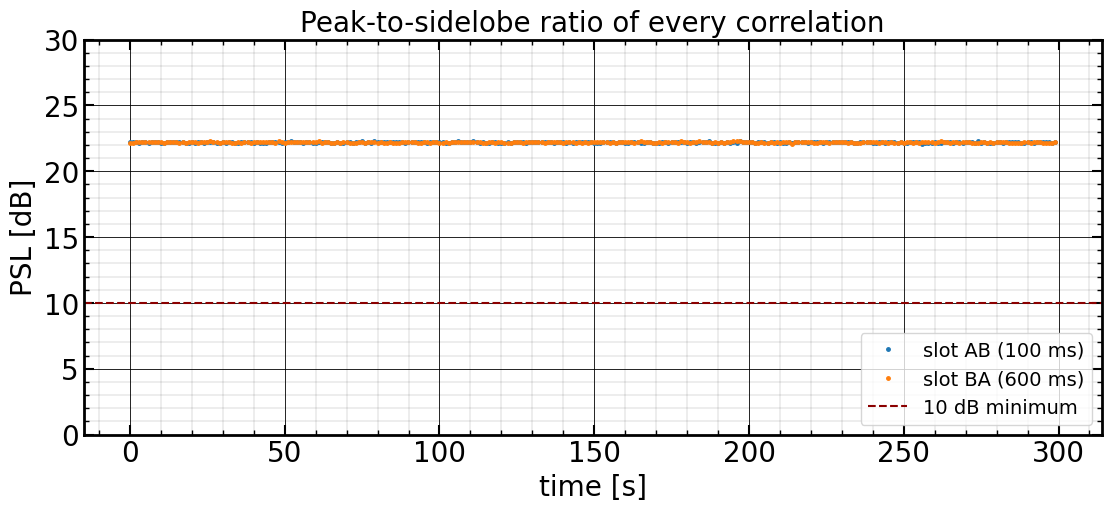

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(11, 5), layout='constrained')
ax.plot(t, psl_ab, ".", ms=5, color="tab:blue", label="slot AB (100 ms)")
ax.plot(t, psl_ba, ".", ms=5, color="tab:orange", label="slot BA (600 ms)")
ax.axhline(10, color="darkred", ls="--", lw=1.5, label="10 dB minimum")
ax.set_ylim(0, 30)
ax.set_xlabel("time [s]"); ax.set_ylabel("PSL [dB]")
ax.set_title("Peak-to-sidelobe ratio of every correlation", fontsize=20)
ax.legend(fontsize=14, loc="lower right"); grids(ax)
fig.savefig(FIG / "psl.png", dpi=150); plt.show()

## 6. The two one-way measurements

On one board $m_{AB}$ and $m_{BA}$ are the same quantity, the loopback delay, measured 500 ms apart. Shown as deviations from their common mean.

m_AB: mean 287.1095 ns, sdev 1.85 ps
m_BA: mean 287.1094 ns, sdev 1.80 ps
correlation between m_AB and m_BA of the same second: +0.16


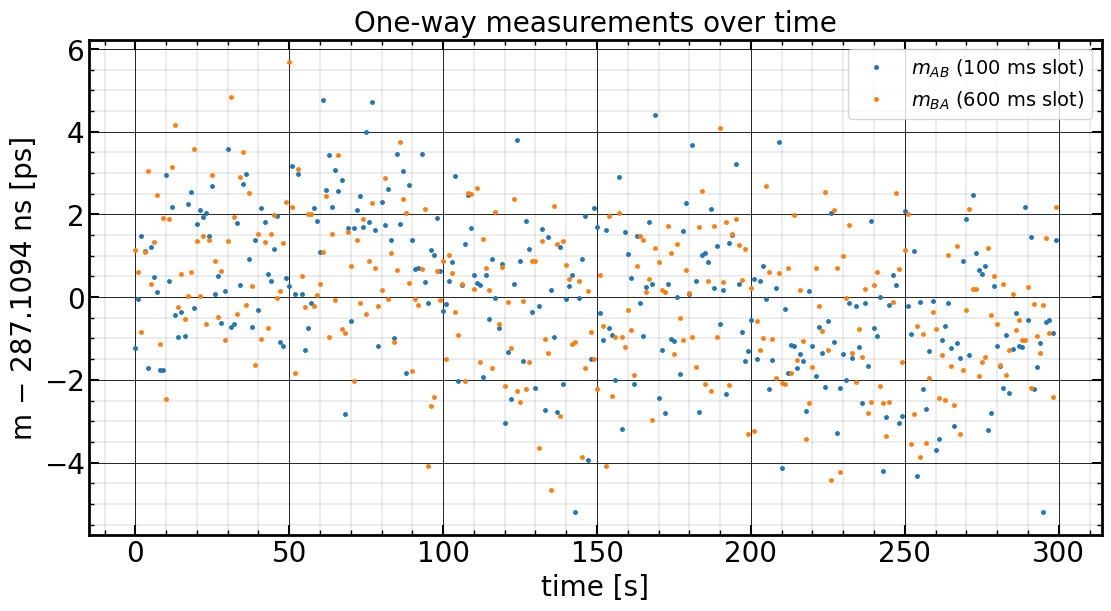

In [8]:
mean_m = np.nanmean(np.r_[m_ab, m_ba])
for name, m in (("m_AB", m_ab), ("m_BA", m_ba)):
    print(f"{name}: mean {np.nanmean(m):.4f} ns, sdev {np.nanstd(m, ddof=1) * 1e3:.2f} ps")
r_ab_ba = np.corrcoef(m_ab[valid], m_ba[valid])[0, 1]
print(f"correlation between m_AB and m_BA of the same second: {r_ab_ba:+.2f}")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, (m_ab - mean_m) * 1e3, ".", ms=5, color="tab:blue", label="$m_{AB}$ (100 ms slot)")
ax.plot(t, (m_ba - mean_m) * 1e3, ".", ms=5, color="tab:orange", label="$m_{BA}$ (600 ms slot)")
ax.set_xlabel("time [s]"); ax.set_ylabel(f"m − {mean_m:.4f} ns [ps]")
ax.set_title("One-way measurements over time", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
fig.savefig(FIG / "one_way.png", dpi=150); plt.show()

## 7. The clock offset θ

$\theta = (m_{AB} - m_{BA})/2$. Expected: 0. Its scatter is the precision of one second of two-way time transfer on this board; anything common to both slots (slow drift of the cable, the filter or the board) cancels.

theta: mean +0.060 ps +/- 0.068 ps (standard error), sdev 1.18 ps, min -2.78, max +3.23 ps over 300 s
expected sdev if the two slots were independent: sd(m)/sqrt(2) = 1.31 ps
skewness +0.08, excess kurtosis -0.44, Shapiro-Wilk p = 0.19


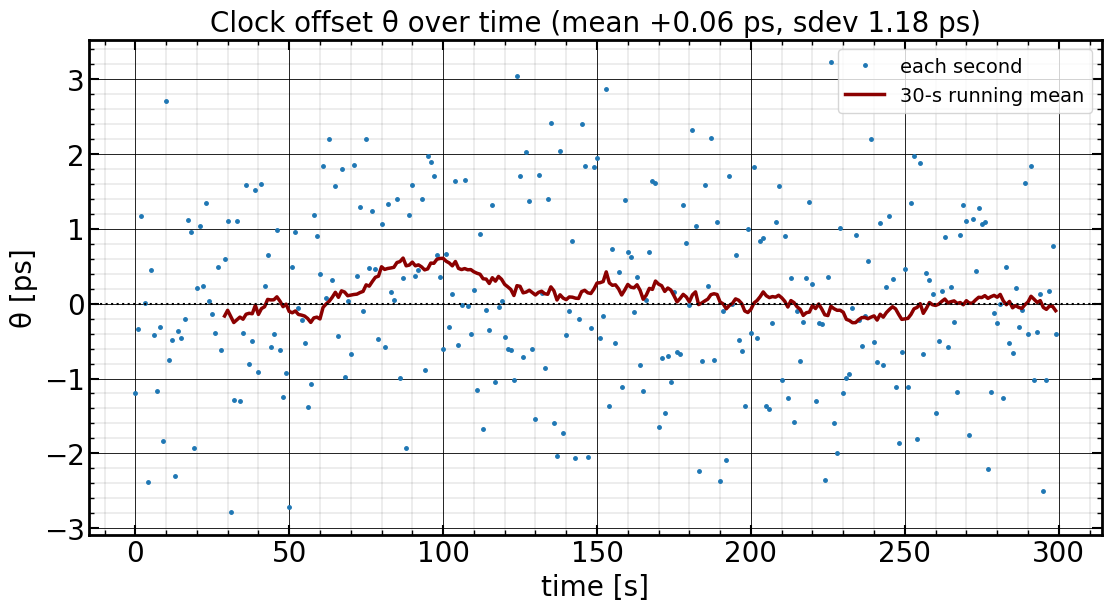

In [9]:
th_ps = theta[valid] * 1e3
th_mean, th_sd = th_ps.mean(), th_ps.std(ddof=1)
sem = th_sd / np.sqrt(th_ps.size)
print(f"theta: mean {th_mean:+.3f} ps +/- {sem:.3f} ps (standard error), sdev {th_sd:.2f} ps, "
      f"min {th_ps.min():+.2f}, max {th_ps.max():+.2f} ps over {th_ps.size} s")
print(f"expected sdev if the two slots were independent: sd(m)/sqrt(2) = "
      f"{np.nanstd(m_ab, ddof=1) * 1e3 / np.sqrt(2):.2f} ps")
print(f"skewness {stats.skew(th_ps):+.2f}, excess kurtosis {stats.kurtosis(th_ps):+.2f}, "
      f"Shapiro-Wilk p = {stats.shapiro(th_ps).pvalue:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t[valid], th_ps, ".", ms=5, color="tab:blue", label="each second")
ax.plot(t[valid][29:], np.convolve(th_ps, np.ones(30) / 30, mode="valid"), "-", color="darkred", lw=2.5,
        label="30-s running mean")
ax.axhline(0, color="k", ls=":", lw=1.5)
ax.set_xlabel("time [s]"); ax.set_ylabel("θ [ps]")
ax.set_title(f"Clock offset θ over time (mean {th_mean:+.2f} ps, sdev {th_sd:.2f} ps)", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
fig.savefig(FIG / "theta_time.png", dpi=150); plt.show()

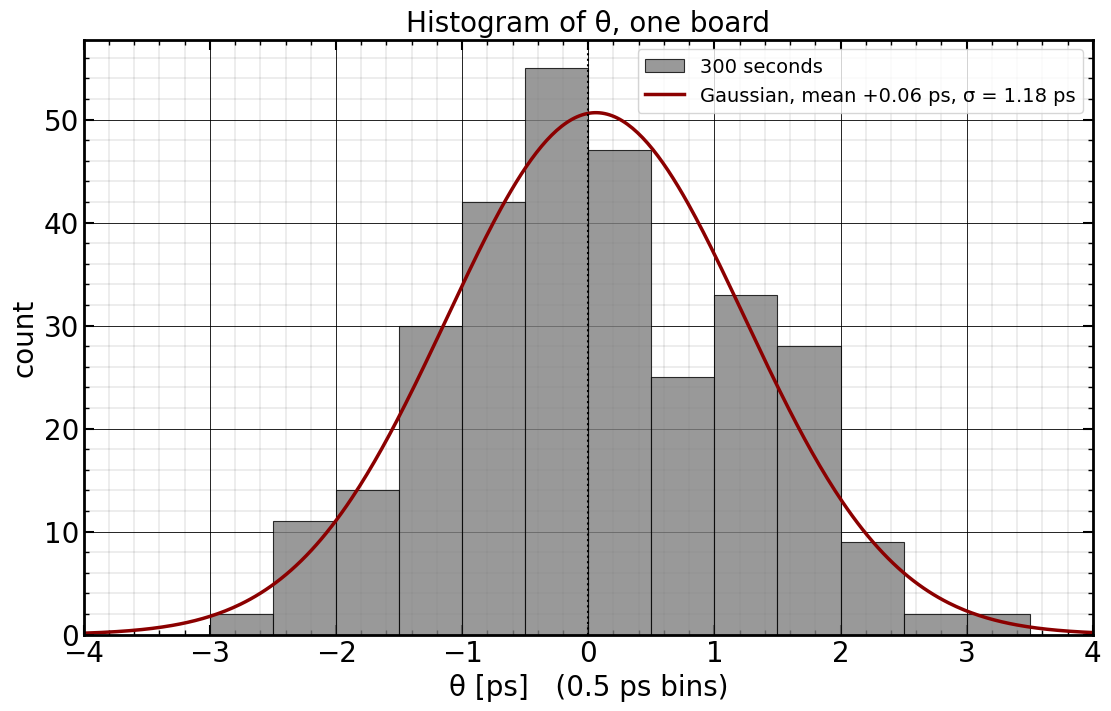

In [10]:
BIN_PS = 0.5
edge = BIN_PS * np.ceil(np.abs(th_ps).max() / BIN_PS + 1)
bins = np.arange(-edge, edge + BIN_PS / 2, BIN_PS)        # equal bins, symmetric about 0
x = np.linspace(bins[0], bins[-1], 400)

fig, ax = plt.subplots(1, 1, figsize=(11, 7), layout='constrained')
ax.hist(th_ps, bins=bins, color="grey", edgecolor="k", lw=0.8, alpha=0.8, label=f"{th_ps.size} seconds")
ax.plot(x, th_ps.size * BIN_PS * stats.norm.pdf(x, th_mean, th_sd), "-", color="darkred", lw=2.5,
        label=f"Gaussian, mean {th_mean:+.2f} ps, σ = {th_sd:.2f} ps")
ax.axvline(0, color="k", ls=":", lw=1.5)
ax.set_xlim(bins[0], bins[-1])
ax.set_xlabel(f"θ [ps]   ({BIN_PS} ps bins)"); ax.set_ylabel("count")
ax.set_title("Histogram of θ, one board", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
fig.savefig(FIG / "theta_histogram.png", dpi=150); plt.show()

## 8. The one-way delay

$(m_{AB} + m_{BA})/2$: on one board, the loopback delay. Here the slow variations do **not** cancel, so it should look like M3 measured continuously.

one-way delay: mean 287.1094 ns, sdev 1.39 ps, trend -0.48 ps/min
difference from M3 (287.1142 ns): -4.77 ps


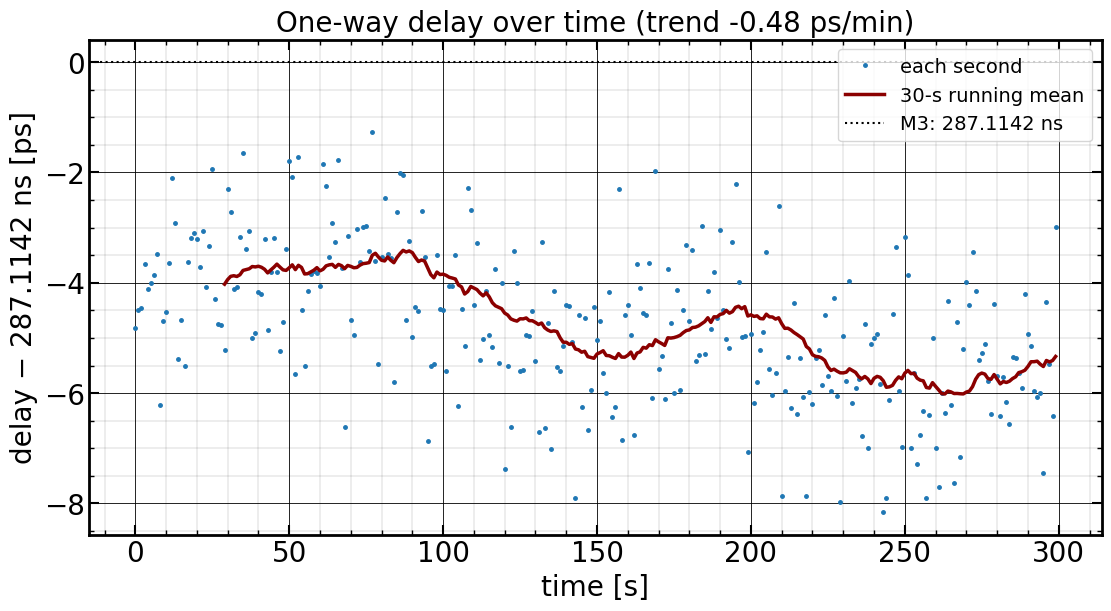

In [11]:
dl_ps = (delay[valid] - M3_NS) * 1e3
slope = np.polyfit(t[valid], delay[valid], 1)[0] * 1e3 * 60
print(f"one-way delay: mean {np.nanmean(delay):.4f} ns, sdev {np.nanstd(delay, ddof=1) * 1e3:.2f} ps, "
      f"trend {slope:+.2f} ps/min")
print(f"difference from M3 ({M3_NS} ns): {dl_ps.mean():+.2f} ps")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t[valid], dl_ps, ".", ms=5, color="tab:blue", label="each second")
ax.plot(t[valid][29:], np.convolve(dl_ps, np.ones(30) / 30, mode="valid"), "-", color="darkred", lw=2.5,
        label="30-s running mean")
ax.axhline(0, color="k", ls=":", lw=1.5, label=f"M3: {M3_NS} ns")
ax.set_xlabel("time [s]"); ax.set_ylabel(f"delay − {M3_NS} ns [ps]")
ax.set_title(f"One-way delay over time (trend {slope:+.2f} ps/min)", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
fig.savefig(FIG / "delay_time.png", dpi=150); plt.show()

## 9. Stability with averaging

Two views:

* the **standard deviation of the mean of N consecutive seconds**, for θ and for the one-way delay. For white noise it falls as $1/\sqrt{N}$.
* the **overlapping Allan deviation** of θ, treating θ as the time error $x(t)$ between the two "clocks" (here one clock against itself): $\sigma_y(\tau) = \sqrt{\langle (x_{i+2m} - 2x_{i+m} + x_i)^2 \rangle / (2\tau^2)}$ with $\tau = m$ seconds. It is the fractional frequency instability the link could resolve; for white time noise it falls as $1/\tau$. This is the quantity reported for the two-board test of 21 October (5.0e-12 at 1 s).

N =   1: theta  1.18 ps   one-way delay  1.39 ps
N =   2: theta  0.78 ps   one-way delay  1.16 ps
N =   5: theta  0.48 ps   one-way delay  0.92 ps
N =  10: theta  0.37 ps   one-way delay  0.88 ps
N =  20: theta  0.28 ps   one-way delay  0.83 ps
N =  30: theta  0.23 ps   one-way delay  0.88 ps
N =  60: theta  0.23 ps   one-way delay  0.81 ps


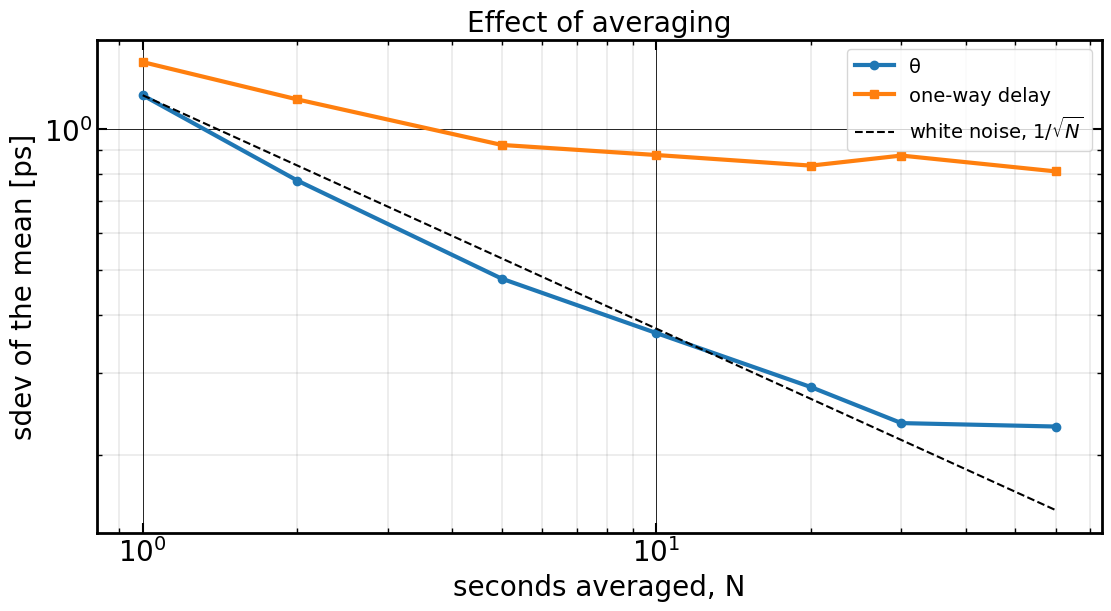

In [12]:
def sd_of_mean(y, Ns):
    out = []
    for n in Ns:
        k = y.size // n
        out.append(y[: k * n].reshape(k, n).mean(axis=1).std(ddof=1))
    return np.array(out)

def oadev(x_s, taus):
    out = []
    for m in taus:
        d = x_s[2 * m:] - 2 * x_s[m:-m] + x_s[:-2 * m]
        out.append(np.sqrt(np.mean(d ** 2) / (2 * m ** 2)))
    return np.array(out)

Ns = np.array([1, 2, 5, 10, 20, 30, 60])
sd_th, sd_dl = sd_of_mean(th_ps, Ns), sd_of_mean(delay[valid] * 1e3, Ns)
for n, a, b in zip(Ns, sd_th, sd_dl):
    print(f"N = {n:3d}: theta {a:5.2f} ps   one-way delay {b:5.2f} ps")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(Ns, sd_th, "o-", color="tab:blue", label="θ")
ax.loglog(Ns, sd_dl, "s-", color="tab:orange", label="one-way delay")
ax.loglog(Ns, sd_th[0] / np.sqrt(Ns), "k--", lw=1.5, label="white noise, $1/\\sqrt{N}$")
ax.set_xlabel("seconds averaged, N"); ax.set_ylabel("sdev of the mean [ps]")
ax.set_title("Effect of averaging", fontsize=20)
ax.legend(fontsize=14); grids(ax)
fig.savefig(FIG / "averaging.png", dpi=150); plt.show()

tau =   1 s: ADEV 2.13e-12
tau =   2 s: ADEV 1.07e-12
tau =   4 s: ADEV 4.95e-13
tau =   5 s: ADEV 4.53e-13
tau =   8 s: ADEV 2.46e-13
tau =  12 s: ADEV 1.76e-13
tau =  19 s: ADEV 1.02e-13
tau =  28 s: ADEV 7.26e-14
tau =  43 s: ADEV 4.95e-14
tau =  66 s: ADEV 3.08e-14
tau = 100 s: ADEV 2.20e-14


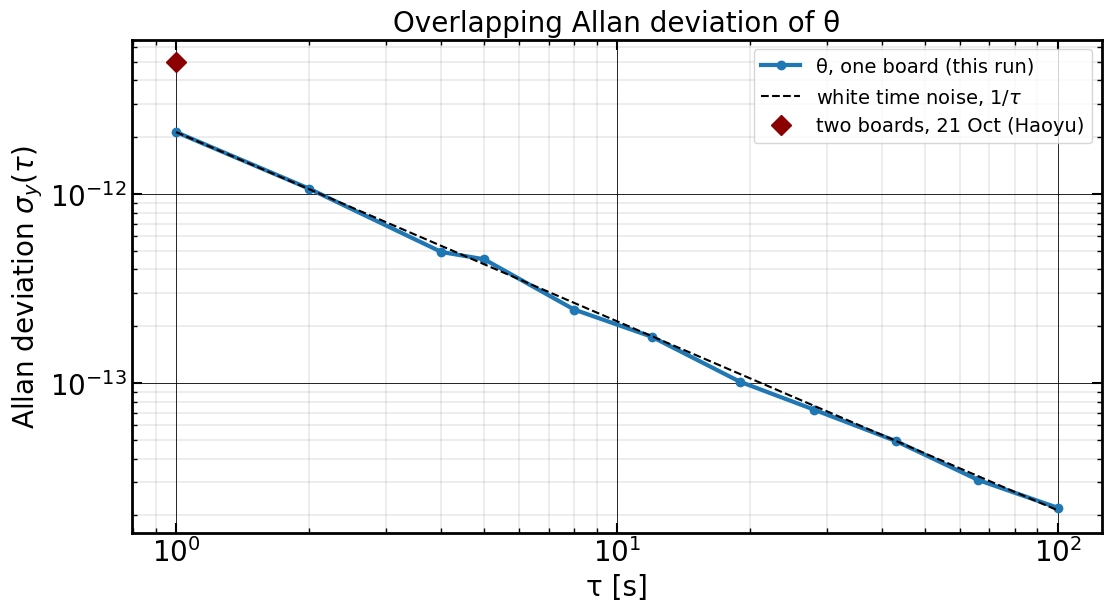

In [13]:
taus = np.unique(np.round(np.logspace(0, np.log10(th_ps.size // 3), 12)).astype(int))
ad = oadev(th_ps * 1e-12, taus)
for tau, a in zip(taus, ad):
    print(f"tau = {tau:3d} s: ADEV {a:.2e}")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(taus, ad, "o-", color="tab:blue", label="θ, one board (this run)")
ax.loglog(taus, ad[0] / taus, "k--", lw=1.5, label="white time noise, $1/\\tau$")
ax.loglog([1], [5.0e-12], "D", color="darkred", ms=10, label="two boards, 21 Oct (Haoyu)")
ax.set_xlabel("τ [s]"); ax.set_ylabel("Allan deviation $\\sigma_y(\\tau)$")
ax.set_title("Overlapping Allan deviation of θ", fontsize=20)
ax.legend(fontsize=14); grids(ax)
fig.savefig(FIG / "allan.png", dpi=150); plt.show()

## 10. Comparison

In [14]:
rows = [
    ("M3 loopback, this cabling (20 captures)", f"{M3_NS:.4f} ns", f"{M3_SD_PS:.1f} ps", "—"),
    ("TWTT self-test, one-way delay", f"{np.nanmean(delay):.4f} ns", f"{np.nanstd(delay, ddof=1) * 1e3:.1f} ps", "—"),
    ("TWTT self-test, θ (truth 0)", f"{th_mean:+.2f} ps", f"{th_sd:.2f} ps", f"{ad[0]:.1e}"),
    ("Two boards, 21 Oct, θ (Haoyu, 600 s)", "+9.8778 ns*", "2.95 ps", "5.0e-12"),
]
print(f"{'':42s} {'mean':>14s} {'sdev':>9s} {'ADEV(1 s)':>10s}")
for r in rows:
    print(f"{r[0]:42s} {r[1]:>14s} {r[2]:>9s} {r[3]:>10s}")
print("* one tick (10 ns) of PPS path difference between Haoyu's two boards plus their non-reciprocity")

                                                     mean      sdev  ADEV(1 s)
M3 loopback, this cabling (20 captures)       287.1142 ns    2.0 ps          —
TWTT self-test, one-way delay                 287.1094 ns    1.4 ps          —
TWTT self-test, θ (truth 0)                      +0.06 ps   1.18 ps    2.1e-12
Two boards, 21 Oct, θ (Haoyu, 600 s)          +9.8778 ns*   2.95 ps    5.0e-12
* one tick (10 ns) of PPS path difference between Haoyu's two boards plus their non-reciprocity


## 11. Summary

**The self-test passes.** The two-way time transfer program ran on this board for 300 s with every second complete and valid, and it recovers the known answer.

* **Completeness:** 300 of 300 seconds paired and valid, no missed PPS, no slot errors, no events. Every correlation had a PSL of 22.1–22.3 dB (10 dB needed). The ARM keeps up with two timed bursts, two captures and two correlations every second.
* **Arithmetic checked by hand:** recomputing the first second from its raw ticks and correlation peaks gives exactly the logged $m_{AB}$, $m_{BA}$, θ and delay.
* **θ = +0.06 ± 0.07 ps** (mean ± standard error; the truth is 0), **1.18 ps standard deviation per second**, Gaussian. That is the single-second precision of TWTT with this board, signal level and cabling.
* **θ is white noise.** Its Allan deviation falls exactly as 1/τ, from **2.1e-12 at 1 s to 2.2e-14 at 100 s**, and averaging 30 s brings θ to about 0.2 ps. The 1.18 ps is slightly below what two independent slots would give (1.31 ps), because $m_{AB}$ and $m_{BA}$ of one second are weakly correlated (+0.16): some noise is common to both slots and cancels.
* **The one-way delay is not white:** it drifts by about −0.5 ps/min (2 ps over the 5 minutes), so averaging stops helping at about 0.8 ps. That drift is common to both directions and **cancels in θ**, which is exactly what the two-way method is for. Its cause (temperature of the cable, filter or board) is not identified.
* **One-way delay 287.1094 ns,** 4.8 ps below the M3 value from 6 minutes earlier (287.1142 ns). Between the two runs the board was powered up again (clocks and MTS), and the delay was drifting at −0.5 ps/min, so a few ps is expected; Haoyu's boards repeat to 2.4–3.5 ps (sd) across clock restarts. The ADC MTS offset of tile 2 read 8 in this run (10 in M3) with the same latency 1296.

**Compared with the two-board test of 21 October** (Haoyu's two boards, 600 s): θ standard deviation 2.95 ps and Allan deviation 5.0e-12 at 1 s there, against 1.18 ps and 2.1e-12 here. The self-test is better, as it should be: one board through one cable has a single clock and no inter-board path, so its noise is only the measurement's own (correlation noise at this SNR). The two-board numbers add the second board, the two boards' clocks wandering against each other and two separate cables. **The one-board result is the floor that the two-board test can approach.**

**What it does not show:** a real clock offset, the non-reciprocity Δ between two boards, the inter-board cables, and the network pairing. Those come with the two-board test.

**Before the two-board test** (see the checklist in the conversation of this date): PPS capture margin on EPG1 output 2 (with Haoyu, since it restarts the EPG1), the same 10 MHz distribution for both boards, one band-pass filter and attenuator per direction, and which second board and EPG1 output to use.

Files: log `rf_clock_board/logs/twtt_AB_20261027_232952.jsonl` (and the console output `.log`), figures `rf_clock_board/twtt/twtt_AB_20261027_232952/`.
